# Phase 2 – Notebook 3: Ablation Studies

**What is an ablation?** We change or remove **one thing** at a time and see what happens to the score. This shows which parts of the model really help.

We test 7 groups:
- **A** Embeddings vs one-hot encoding
- **B** With vs without the history features
- **C** Dropout (0.0, 0.2, 0.3, 0.5)
- **D** Weight decay (0, 1e-4, 1e-3)
- **E** Embedding size (small, default, large)
- **F** With vs without class weight
- **G** Logistic Regression vs MLP

**Rules:** same data, same split, same seed (42) for every run. The test set is never used to choose anything. We mainly compare **PR AUC** and **ROC AUC**, because they do not depend on a threshold.

In [1]:
import sys, os, time
from pathlib import Path

# Work from the project root so imports and paths always work
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

metrics_dir = ROOT / "reports" / "metrics"
fig_dir = ROOT / "reports" / "figures"
metrics_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)


def to_md(df, digits=4):
    """Turn a DataFrame into a markdown table (used for the report)."""
    cols = list(df.columns)
    lines = ["| " + " | ".join(str(c) for c in cols) + " |",
             "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        cells = [f"{v:.{digits}f}" if isinstance(v, (float, np.floating)) else str(v) for v in r.values]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines) + "\n"


print("Project root:", ROOT)

Project root: /Users/atharvatiwari/Desktop/flight-delay-prediction


## 1. Load data and split by time
Same split as Notebooks 1 and 2.

In [2]:
from src.data_loader import load_data
from src.preprocessing import clean_data, create_target
from src.phase2_history_features import add_history_features, PHASE2_NUMERIC_FEATURES, PHASE2_FEATURE_COLUMNS

df_p2, _ = add_history_features(create_target(clean_data(load_data())), train_ratio=0.70)

n = len(df_p2)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train_df = df_p2.iloc[:train_end].copy()
val_df   = df_p2.iloc[train_end:val_end].copy()
test_df  = df_p2.iloc[val_end:].copy()
y_train, y_val, y_test = train_df["delayed"].values, val_df["delayed"].values, test_df["delayed"].values

print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
print(f"Delay rate -> train {y_train.mean():.3f} | validation {y_val.mean():.3f} | test {y_test.mean():.3f}")

Train: 229,142 | Validation: 49,102 | Test: 49,102
Delay rate -> train 0.259 | validation 0.154 | test 0.267


## 2. Helper functions
`run_emb` trains one embedding MLP, tests it, and writes one row into the results list. All runs use the same early stopping rule (max 40 epochs, patience 5).

In [3]:
from src.feature_engineering import NUMERIC_FEATURES, CATEGORICAL_FEATURES
from src.dl_model import train_mlp_model
from src.phase2_ablations import (
    train_onehot_mlp, evaluate_mlp_on_test, evaluate_onehot_mlp_on_test, plot_ablation_group,
)

records = []

def log(group, variant, m):
    """Save one result row and print it."""
    records.append({
        "group": group, "variant": variant,
        **{k: float(m[k]) for k in ["threshold", "pr_auc", "roc_auc", "precision", "recall", "f1", "brier_score"]},
    })
    print(f"{group:20s} | {variant:42s} | PR AUC {m['pr_auc']:.4f} | ROC AUC {m['roc_auc']:.4f}")

def run_emb(group, variant, numeric_cols=PHASE2_NUMERIC_FEATURES, **kwargs):
    """Train an embedding MLP with the given settings and evaluate it on the test set."""
    model, art, _ = train_mlp_model(train_df, val_df, numeric_cols, max_epochs=40, patience=5, seed=42, **kwargs)
    m = evaluate_mlp_on_test(model, art, test_df, val_df, target_precision=0.40)
    log(group, variant, m)
    return m

## 3. Groups A and B: embeddings and history features
- **A:** the default MLP (embeddings) against an MLP that uses one-hot encoding for carrier / origin / dest.
- **B:** the default MLP (with history features) against an MLP that only has the Phase 1 features.

In [4]:
t0 = time.time()

# Default model: it is the reference in many groups
default_m = run_emb("A: Architecture", "MLP with Embeddings (Default)")

# A: one-hot instead of embeddings
oh_model, oh_scaler, oh_enc = train_onehot_mlp(
    train_df, val_df, PHASE2_NUMERIC_FEATURES, CATEGORICAL_FEATURES,
    dropout=0.3, weight_decay=1e-4, max_epochs=40, patience=5, seed=42,
)
oh_m = evaluate_onehot_mlp_on_test(
    oh_model, oh_scaler, oh_enc, test_df, val_df,
    PHASE2_NUMERIC_FEATURES, CATEGORICAL_FEATURES, target_precision=0.40,
)
log("A: Architecture", "MLP with One-Hot Encoding", oh_m)

# B: with and without history features
log("B: Features", "With History Features (Default)", default_m)
run_emb("B: Features", "Without History Features (Phase 1 Features)", numeric_cols=NUMERIC_FEATURES)

print(f"\nDone in {time.time() - t0:.0f} seconds.")

A: Architecture      | MLP with Embeddings (Default)              | PR AUC 0.4725 | ROC AUC 0.6690
A: Architecture      | MLP with One-Hot Encoding                  | PR AUC 0.4803 | ROC AUC 0.6771
B: Features          | With History Features (Default)            | PR AUC 0.4725 | ROC AUC 0.6690
B: Features          | Without History Features (Phase 1 Features) | PR AUC 0.3239 | ROC AUC 0.5889

Done in 26 seconds.


## 4. Groups C and D: regularization
- **C – Dropout:** how many neurons we switch off while training.
- **D – Weight decay:** how strongly we punish large weights.

Both fight overfitting. If the scores barely change, the model is not very sensitive to them.

In [5]:
t0 = time.time()

# C: dropout
for drop in [0.0, 0.2, 0.3, 0.5]:
    if drop == 0.3:
        log("C: Dropout", "Dropout 0.3 (Default)", default_m)
    else:
        run_emb("C: Dropout", f"Dropout {drop}", dropout=drop)

# D: weight decay
for wd, label in [(0.0, "No Weight Decay (0.0)"), (1e-4, "Weight Decay 1e-4 (Default)"), (1e-3, "Weight Decay 1e-3")]:
    if wd == 1e-4:
        log("D: Weight Decay", label, default_m)
    else:
        run_emb("D: Weight Decay", label, weight_decay=wd)

print(f"\nDone in {time.time() - t0:.0f} seconds.")

C: Dropout           | Dropout 0.0                                | PR AUC 0.4794 | ROC AUC 0.6768
C: Dropout           | Dropout 0.2                                | PR AUC 0.4795 | ROC AUC 0.6770
C: Dropout           | Dropout 0.3 (Default)                      | PR AUC 0.4725 | ROC AUC 0.6690
C: Dropout           | Dropout 0.5                                | PR AUC 0.4783 | ROC AUC 0.6744
D: Weight Decay      | No Weight Decay (0.0)                      | PR AUC 0.4721 | ROC AUC 0.6685
D: Weight Decay      | Weight Decay 1e-4 (Default)                | PR AUC 0.4725 | ROC AUC 0.6690
D: Weight Decay      | Weight Decay 1e-3                          | PR AUC 0.4718 | ROC AUC 0.6682

Done in 51 seconds.


## 5. Groups E and F: embedding size and class weight
- **E:** small (2, 2, 4), default (4, 3, 8) and large (8, 6, 16) embeddings for carrier, origin and destination.
- **F:** training with and without `pos_weight` (extra weight on delayed flights).

Note: without `pos_weight` the probabilities are not pushed up, so the threshold chosen on validation will be different.

In [6]:
t0 = time.time()

# E: embedding size
log("E: Embedding Size", "Default (4, 3, 8)", default_m)
run_emb("E: Embedding Size", "Small (2, 2, 4)", carrier_dim=2, origin_dim=2, dest_dim=4)
run_emb("E: Embedding Size", "Large (8, 6, 16)", carrier_dim=8, origin_dim=6, dest_dim=16)

# F: class weighting
log("F: Class Weighting", "With pos_weight (Default)", default_m)
run_emb("F: Class Weighting", "Without pos_weight (Unweighted)", use_pos_weight=False)

print(f"\nDone in {time.time() - t0:.0f} seconds.")

E: Embedding Size    | Default (4, 3, 8)                          | PR AUC 0.4725 | ROC AUC 0.6690
E: Embedding Size    | Small (2, 2, 4)                            | PR AUC 0.4699 | ROC AUC 0.6697
E: Embedding Size    | Large (8, 6, 16)                           | PR AUC 0.4803 | ROC AUC 0.6803
F: Class Weighting   | With pos_weight (Default)                  | PR AUC 0.4725 | ROC AUC 0.6690
F: Class Weighting   | Without pos_weight (Unweighted)            | PR AUC 0.4741 | ROC AUC 0.6701

Done in 32 seconds.


## 6. Group G: final model comparison
Logistic Regression (Phase 2 features) comes from the table saved by Notebook 1. The MLP is the default model from above.

In [7]:
baseline_path = metrics_dir / "phase2_baseline_comparison.csv"
assert baseline_path.exists(), "Run Notebook 1 first (it creates phase2_baseline_comparison.csv)."
base = pd.read_csv(baseline_path)

for model_name in ["Logistic Regression"]:
    row = base[(base["Model"] == model_name) & (base["Features"].str.startswith("Phase 2"))].iloc[0]
    log("G: Model Comparison", f"{model_name} (Phase 2)", row.to_dict())
log("G: Model Comparison", "PyTorch MLP (Phase 2)", default_m)

G: Model Comparison  | Logistic Regression (Phase 2)              | PR AUC 0.4695 | ROC AUC 0.6676
G: Model Comparison  | PyTorch MLP (Phase 2)                      | PR AUC 0.4725 | ROC AUC 0.6690


## 7. Full results table
This table is saved in `reports/metrics/` and is the main source for the report.

In [8]:
ablation_df = pd.DataFrame(records)
ablation_df.to_csv(metrics_dir / "phase2_ablation_results.csv", index=False)
with open(metrics_dir / "phase2_ablation_results.md", "w") as f:
    f.write(to_md(ablation_df.rename(columns={
        "group": "Group", "variant": "Variant", "threshold": "Threshold", "pr_auc": "PR AUC",
        "roc_auc": "ROC AUC", "precision": "Precision", "recall": "Recall", "f1": "F1", "brier_score": "Brier"})))
ablation_df.round(4)

,group,variant,threshold,pr_auc,roc_auc,precision,recall,f1,brier_score
0,A: Architecture,MLP with Embeddings (Default),0.4706,0.4725,0.6690,0.6002,0.2347,0.3374,0.1789
1,A: Architecture,MLP with One-Hot Encoding,0.4570,0.4803,0.6771,0.6182,0.2284,0.3336,0.1766
2,B: Features,With History Features (Default),0.4706,0.4725,0.6690,0.6002,0.2347,0.3374,0.1789
3,B: Features,Without History Features (Phase 1 Features),0.7148,0.3239,0.5889,0.0000,0.0000,0.0000,0.1948
4,C: Dropout,Dropout 0.0,0.4661,0.4794,0.6768,0.5927,0.2495,0.3512,0.1765
5,C: Dropout,Dropout 0.2,0.4751,0.4795,0.6770,0.5632,0.2983,0.3900,0.1796
6,C: Dropout,Dropout 0.3 (Default),0.4706,0.4725,0.6690,0.6002,0.2347,0.3374,0.1789
7,C: Dropout,Dropout 0.5,0.4751,0.4783,0.6744,0.5755,0.2780,0.3749,0.1816
8,D: Weight Decay,No Weight Decay (0.0),0.4706,0.4721,0.6685,0.6007,0.2348,0.3376,0.1789
9,D: Weight Decay,Weight Decay 1e-4 (Default),0.4706,0.4725,0.6690,0.6002,0.2347,0.3374,0.1789


## 8. Charts
One chart per group is saved in `reports/figures/`. Below, all groups are shown together (PR AUC).

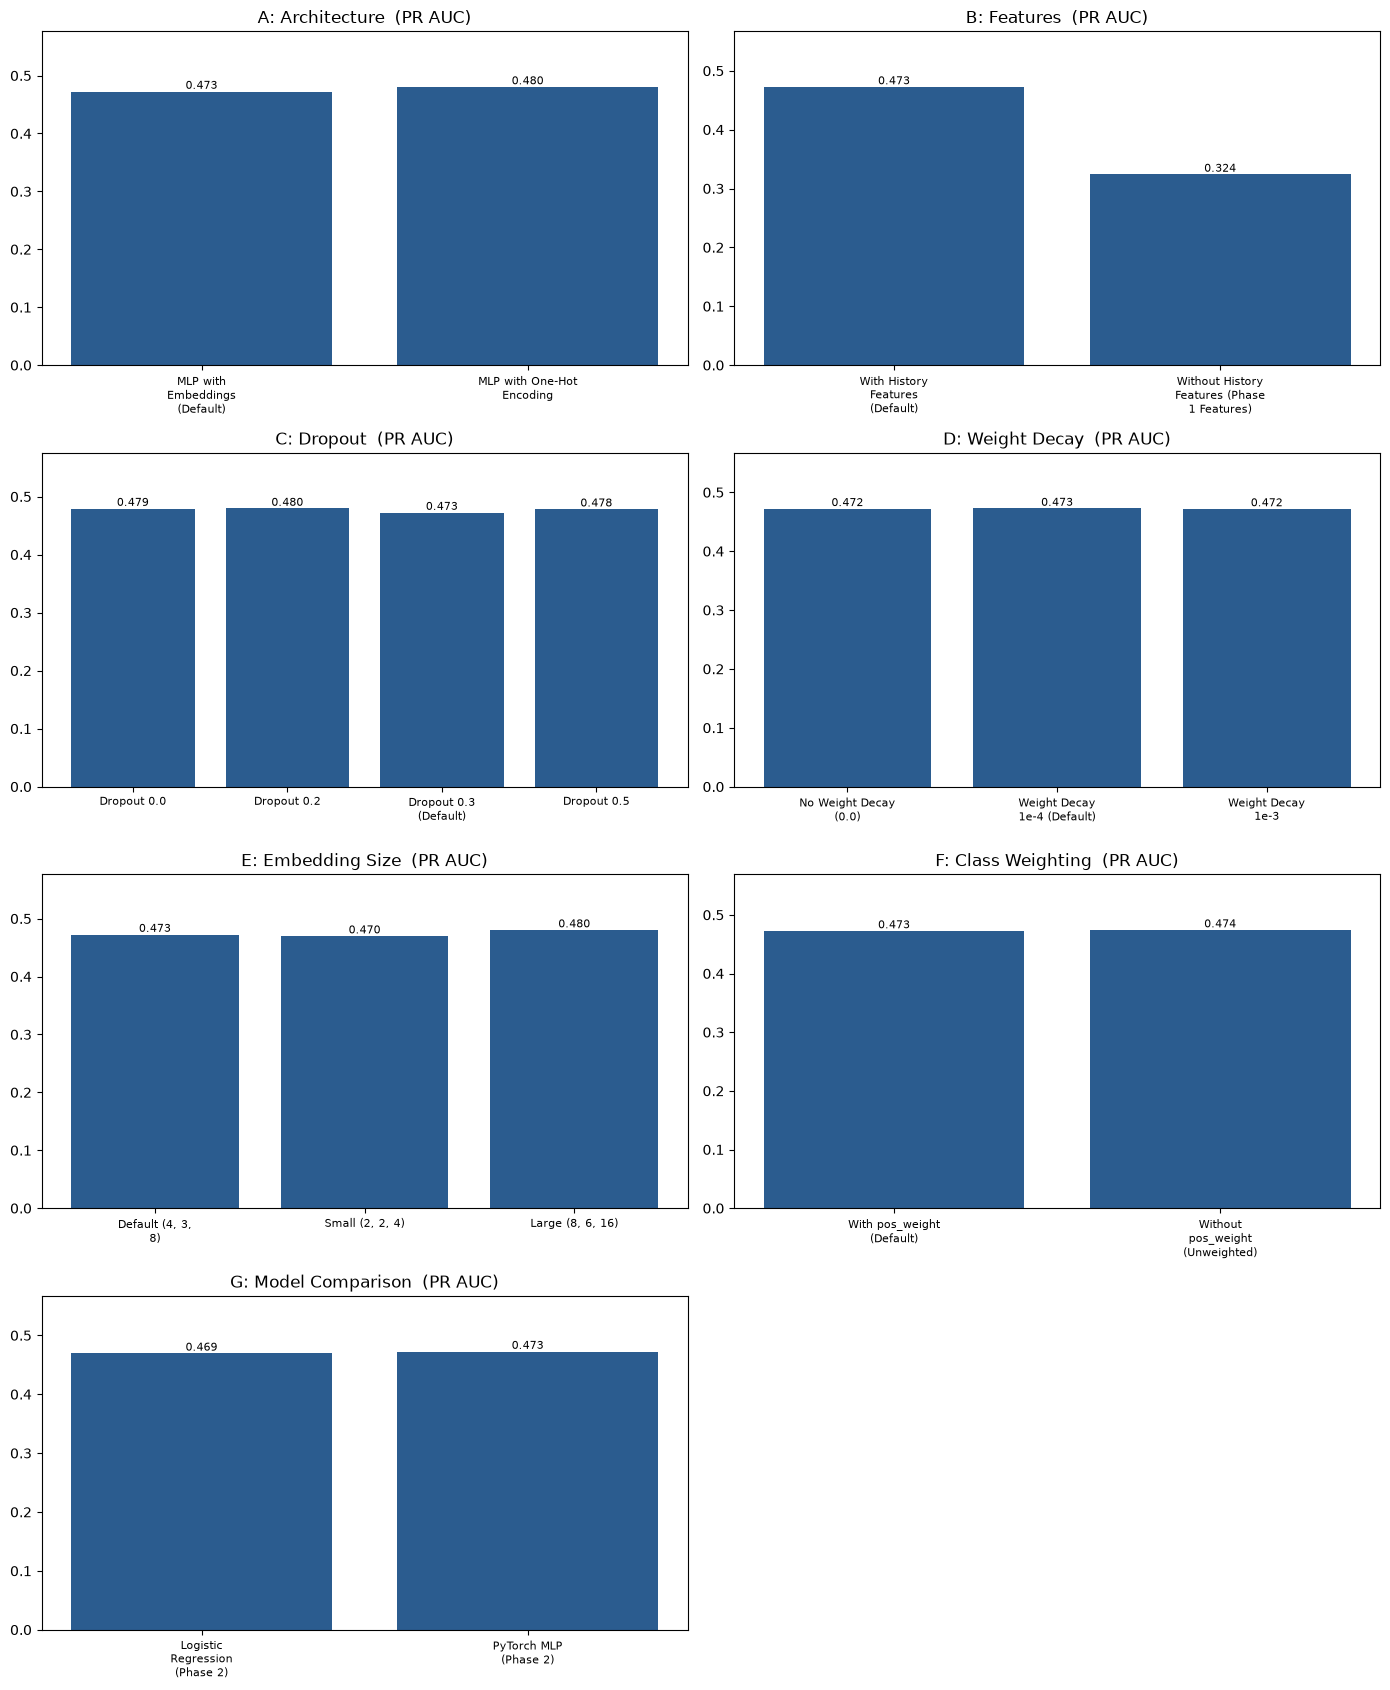

In [9]:
import textwrap

file_names = {
    "A: Architecture": "phase2_ablation_A_embeddings_vs_onehot.png",
    "B: Features": "phase2_ablation_B_history_features.png",
    "C: Dropout": "phase2_ablation_C_dropout.png",
    "D: Weight Decay": "phase2_ablation_D_weight_decay.png",
    "E: Embedding Size": "phase2_ablation_E_embedding_size.png",
    "F: Class Weighting": "phase2_ablation_F_class_weighting.png",
    "G: Model Comparison": "phase2_ablation_G_model_comparison.png",
}
groups = list(ablation_df["group"].unique())
for g in groups:
    plot_ablation_group(ablation_df[ablation_df["group"] == g], g, file_names[g])

fig, axes = plt.subplots(4, 2, figsize=(14, 17))
axes = axes.ravel()
for ax, g in zip(axes, groups):
    sub = ablation_df[ablation_df["group"] == g]
    bars = ax.bar(range(len(sub)), sub["pr_auc"], color="#2b5c8f")
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels([textwrap.fill(v, 16) for v in sub["variant"]], fontsize=8)
    ax.set_title(g + "  (PR AUC)")
    ax.set_ylim(0, sub["pr_auc"].max() * 1.2)
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
for ax in axes[len(groups):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(fig_dir / "phase2_ablation_all_groups.png", dpi=150)
plt.show()

## 9. How big is random noise?
Neural networks start from random numbers, so two runs with different seeds give slightly different scores. We train the default model with 5 different seeds. If two variants differ by less than this noise, we should **not** claim that one is better.

In [10]:
seed_rows = []
for s in [0, 1, 2, 3, 4]:
    model, art, _ = train_mlp_model(train_df, val_df, PHASE2_NUMERIC_FEATURES, max_epochs=40, patience=5, seed=s)
    m = evaluate_mlp_on_test(model, art, test_df, val_df, target_precision=0.40)
    seed_rows.append({"seed": s, "pr_auc": m["pr_auc"], "roc_auc": m["roc_auc"], "brier_score": m["brier_score"]})
    print(f"seed {s}: PR AUC {m['pr_auc']:.4f} | ROC AUC {m['roc_auc']:.4f}")

seed_df = pd.DataFrame(seed_rows)
seed_df.to_csv(metrics_dir / "phase2_mlp_seed_variation.csv", index=False)

noise = seed_df[["pr_auc", "roc_auc", "brier_score"]].agg(["mean", "std", "min", "max"]).round(4)
print(f"\nSeed-to-seed std of PR AUC: {seed_df['pr_auc'].std():.4f}")
print("Differences between variants that are smaller than about 2x this value are inside the noise.")
noise

seed 0: PR AUC 0.4725 | ROC AUC 0.6743
seed 1: PR AUC 0.4664 | ROC AUC 0.6695
seed 2: PR AUC 0.4780 | ROC AUC 0.6769
seed 3: PR AUC 0.4706 | ROC AUC 0.6740
seed 4: PR AUC 0.4796 | ROC AUC 0.6814

Seed-to-seed std of PR AUC: 0.0054
Differences between variants that are smaller than about 2x this value are inside the noise.


,pr_auc,roc_auc,brier_score
mean,0.4734,0.6752,0.1804
std,0.0054,0.0044,0.0033
min,0.4664,0.6695,0.1777
max,0.4796,0.6814,0.1859


## What we learned
- (We will write the real conclusions here after the results are checked.)
- The history features (group B) are the part that matters most, because they carry new information.
- Many regularization and size changes (groups C, D, E) change the score only a little. Compare each change with the seed noise from section 9 before calling it an improvement.